# LA GENERATION DU DATASET ET LES CLUSTERS DESUIQUILIBRER ET LES ENREGISTRER

In [ ]:
import numpy as np
from sklearn.datasets import make_blobs

# 1) Paramètres globaux

N = 300
K = 5
random_state = 42
rng = np.random.default_rng(random_state)


# 2) Générer des tailles de clusters aléatoires (imbalance)

raw = rng.uniform(low=0.1, high=1.0, size=K)
proportions = raw / raw.sum()
samples_per_center = np.round(proportions * N).astype(int)

diff = N - samples_per_center.sum()
for _ in range(abs(diff)):
    i = rng.integers(0, K)
    samples_per_center[i] += 1 if diff > 0 else -1

assert samples_per_center.sum() == N

print("Random imbalanced sizes per center:", samples_per_center.tolist())

s_balanced = N // K
print("Balanced target size s = N/K:", s_balanced)


# 3) Définir explicitement les centres

centers = np.array([
    [-8,  8],
    [-2, 10],
    [ 3,  3],
    [-7, -6],
    [ 5,  6],
])  # 5 centres en 2D


# 4) Génération du dataset 2D

X, y_true = make_blobs(
    n_samples=samples_per_center,
    centers=centers,
    cluster_std=1.0,
    random_state=random_state
)

# Vérification
unique_labels, counts = np.unique(y_true, return_counts=True)
print("True cluster sizes (imbalanced):", dict(zip(unique_labels, counts)))


# 5) Sauvegarde

np.savez(
    "balanced_kmeans_data_imbalanced.npz",
    X=X,
    y_true=y_true,
    N=N,
    K=K,
    s=s_balanced,
    samples_per_center=samples_per_center,
    centers=centers,
    random_state=random_state,
)

print("Imbalanced dataset saved to 'balanced_kmeans_data_imbalanced.npz'")


Random imbalanced sizes per center: [78, 48, 85, 71, 18]
Balanced target size s = N/K: 60
True cluster sizes (imbalanced): {np.int64(0): np.int64(78), np.int64(1): np.int64(48), np.int64(2): np.int64(85), np.int64(3): np.int64(71), np.int64(4): np.int64(18)}
Imbalanced dataset saved to 'balanced_kmeans_data_imbalanced.npz'


# baseline_balanced_k_means

Loaded dataset: (300, 2) points
K: 5
Target balanced size s = N/K = 60
True (imbalanced) sizes per center: [78, 48, 85, 71, 18]
True cluster sizes (from y_true): {np.int64(0): np.int64(78), np.int64(1): np.int64(48), np.int64(2): np.int64(85), np.int64(3): np.int64(71), np.int64(4): np.int64(18)}


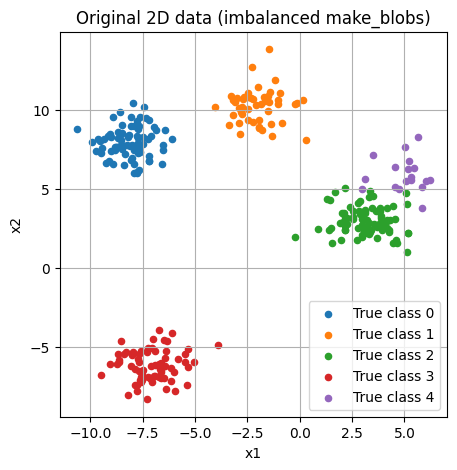

WCSS mean ± std: 17862.97867848285 ± 133.26480249678949
ARI  mean ± std: 0.017051454684428962 ± 0.00570644481097706
Iterations mean: 80.0


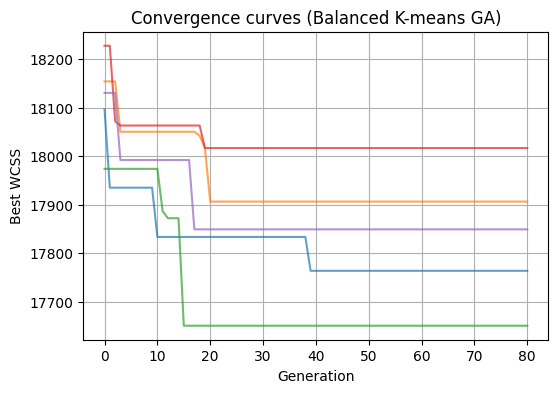

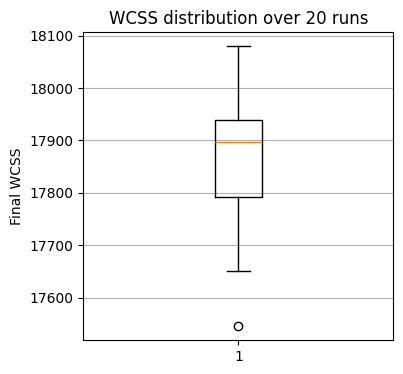

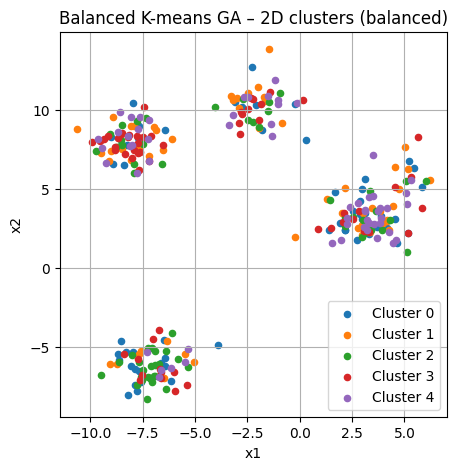

Cluster sizes after GA: [np.int64(60), np.int64(60), np.int64(60), np.int64(60), np.int64(60)]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score


# 1) Charger le dataset imbalanced

data = np.load("balanced_kmeans_data_imbalanced.npz")
X = data["X"]
y_true = data["y_true"]
N = int(data["N"])
K = int(data["K"])
s = int(data["s"])
samples_per_center = data["samples_per_center"]

print("Loaded dataset:", X.shape, "points")
print("K:", K)
print("Target balanced size s = N/K =", s)
print("True (imbalanced) sizes per center:", samples_per_center.tolist())

unique_labels, counts = np.unique(y_true, return_counts=True)
print("True cluster sizes (from y_true):", dict(zip(unique_labels, counts)))

# ---- Visualiser les données originales (clusters réels, imbalanced) ----
plt.figure(figsize=(5,5))
for k in unique_labels:
    idx = np.where(y_true == k)[0]
    plt.scatter(X[idx, 0], X[idx, 1], s=20, label=f"True class {k}")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Original 2D data (imbalanced make_blobs)")
plt.legend()
plt.grid(True)
plt.show()

# 2) Fonctions utilitaires


def compute_centroids(X, z, K):
    d = X.shape[1]
    centroids = np.zeros((K, d))
    for k in range(K):
        idx = np.where(z == k)[0]
        centroids[k] = X[idx].mean(axis=0)
    return centroids

def wcss(X, z, K):
    centroids = compute_centroids(X, z, K)
    total = 0.0
    for k in range(K):
        idx = np.where(z == k)[0]
        diff = X[idx] - centroids[k]
        total += np.sum(diff ** 2)
    return total

def random_balanced_assignment(N, K, s):
    labels = np.repeat(np.arange(K), s)
    assert len(labels) == N
    np.random.shuffle(labels)
    return labels

def init_population(pop_size, N, K, s):
    return np.array([random_balanced_assignment(N, K, s) for _ in range(pop_size)])

def fitness_from_wcss(val):
    return 1.0 / (1.0 + val)

# 3) Opérateurs génétiques (roulette + crossover équilibré + swap)


def roulette_wheel_selection(pop, fitness, pop_size):
    probs = fitness / fitness.sum()
    idx = np.random.choice(len(pop), size=pop_size, replace=True, p=probs)
    return pop[idx]

def repair_balanced(z, K, s):
    z = z.copy()
    counts = np.array([np.sum(z == k) for k in range(K)])
    positions = [np.where(z == k)[0].tolist() for k in range(K)]

    surplus = [k for k in range(K) if counts[k] > s]
    deficit = [k for k in range(K) if counts[k] < s]

    for k_sur in surplus:
        while counts[k_sur] > s:
            if not deficit:
                break
            i = positions[k_sur].pop()
            counts[k_sur] -= 1

            k_def = deficit[0]
            z[i] = k_def
            positions[k_def].append(i)
            counts[k_def] += 1

            if counts[k_def] == s:
                deficit.pop(0)
    return z

def balanced_crossover(parent1, parent2, K, s):
    N = len(parent1)
    mask = np.random.rand(N) < 0.5
    child1 = np.where(mask, parent1, parent2)
    child2 = np.where(mask, parent2, parent1)
    child1 = repair_balanced(child1, K, s)
    child2 = repair_balanced(child2, K, s)
    return child1, child2

def swap_mutation(z):
    z = z.copy()
    i, j = np.random.choice(len(z), size=2, replace=False)
    z[i], z[j] = z[j], z[i]
    return z


# 4) Balanced K-means GA (un run)


def balanced_kmeans_ga(
    X, K, generations=100, pop_size=40, pc=0.8, pm=0.3, seed=None
):
    if seed is not None:
        np.random.seed(seed)

    N = X.shape[0]
    s = N // K

    population = init_population(pop_size, N, K, s)
    wcss_vals = np.array([wcss(X, z, K) for z in population])
    fitness = np.array([fitness_from_wcss(v) for v in wcss_vals])

    best_idx = np.argmax(fitness)
    best_z = population[best_idx].copy()
    best_wcss = wcss_vals[best_idx]

    history = [best_wcss]

    for gen in range(generations):
        mating_pool = roulette_wheel_selection(population, fitness, pop_size)

        new_pop = []
        for i in range(0, pop_size, 2):
            p1 = mating_pool[i]
            p2 = mating_pool[(i + 1) % pop_size]
            if np.random.rand() < pc:
                c1, c2 = balanced_crossover(p1, p2, K, s)
            else:
                c1, c2 = p1.copy(), p2.copy()
            new_pop.extend([c1, c2])
        population = np.array(new_pop[:pop_size])

        for i in range(pop_size):
            if np.random.rand() < pm:
                population[i] = swap_mutation(population[i])

        wcss_vals = np.array([wcss(X, z, K) for z in population])
        fitness = np.array([fitness_from_wcss(v) for v in wcss_vals])

        gen_best_idx = np.argmin(wcss_vals)
        gen_best_wcss = wcss_vals[gen_best_idx]
        if gen_best_wcss < best_wcss:
            best_wcss = gen_best_wcss
            best_z = population[gen_best_idx].copy()

        history.append(best_wcss)

    return best_z, best_wcss, np.array(history)

# =========================
# 5) 20 runs + métriques
# =========================

num_runs = 20
generations = 80

all_wcss = []
all_ari = []
all_iters = []
histories = []

for r in range(num_runs):
    z_best, w_best, hist = balanced_kmeans_ga(
        X, K, generations=generations, pop_size=40, pc=0.8, pm=0.3, seed=100 + r
    )
    all_wcss.append(w_best)
    ari = adjusted_rand_score(y_true, z_best)
    all_ari.append(ari)
    all_iters.append(len(hist) - 1)
    histories.append(hist)

all_wcss = np.array(all_wcss)
all_ari = np.array(all_ari)
all_iters = np.array(all_iters)

print("WCSS mean ± std:", all_wcss.mean(), "±", all_wcss.std())
print("ARI  mean ± std:", all_ari.mean(), "±", all_ari.std())
print("Iterations mean:", all_iters.mean())


# 6) Plots (convergence, boxplot, clusters équilibrés)


# Convergence curves
plt.figure(figsize=(6,4))
for i in range(min(5, num_runs)):
    plt.plot(histories[i], alpha=0.7)
plt.xlabel("Generation")
plt.ylabel("Best WCSS")
plt.title("Convergence curves (Balanced K-means GA)")
plt.grid(True)
plt.show()

# Boxplot WCSS
plt.figure(figsize=(4,4))
plt.boxplot(all_wcss, vert=True)
plt.ylabel("Final WCSS")
plt.title("WCSS distribution over 20 runs")
plt.grid(True, axis='y')
plt.show()

# Clusters 2D après GA (meilleur run)
best_run_idx = np.argmin(all_wcss)
z_best_vis, _, _ = balanced_kmeans_ga(
    X, K, generations=generations, pop_size=40, pc=0.8, pm=0.3, seed=100 + best_run_idx
)

plt.figure(figsize=(5,5))
for k in range(K):
    idx = np.where(z_best_vis == k)[0]
    plt.scatter(X[idx, 0], X[idx, 1], s=20, label=f"Cluster {k}")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Balanced K-means GA – 2D clusters (balanced)")
plt.legend()
plt.grid(True)
plt.show()

print("Cluster sizes after GA:", [np.sum(z_best_vis == k) for k in range(K)])


# IMPROVEMENT APPROACH

Loaded dataset: (300, 2) points
K: 5
Target balanced size s = N/K = 60
True (imbalanced) sizes per center: [78, 48, 85, 71, 18]
True cluster sizes (from y_true): {np.int64(0): np.int64(78), np.int64(1): np.int64(48), np.int64(2): np.int64(85), np.int64(3): np.int64(71), np.int64(4): np.int64(18)}

=== Running improved GA ===
Run 5/20: WCSS=3163.62, ARI=0.6248
Run 10/20: WCSS=3141.62, ARI=0.6292
Run 15/20: WCSS=3121.37, ARI=0.6329
Run 20/20: WCSS=3080.47, ARI=0.6260

=== RESULTS (Improved Version) ===
WCSS mean ± std: 3107.97 ± 91.04
ARI  mean ± std: 0.6284 ± 0.0061
Best WCSS: 2758.77
Best ARI: 0.6391


/tmp/ipython-input-3601068884.py:401: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([all_wcss, all_ari * 10000], labels=['WCSS/100', 'ARI×10000'])


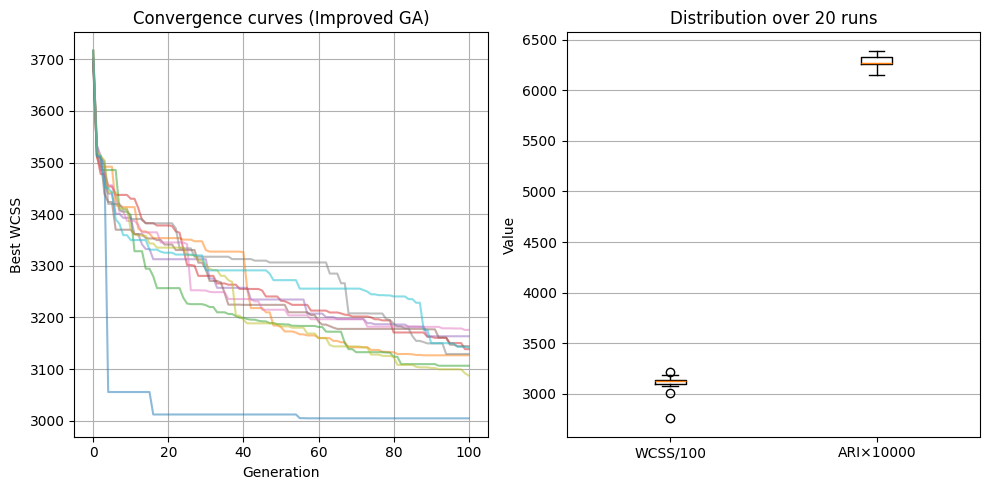

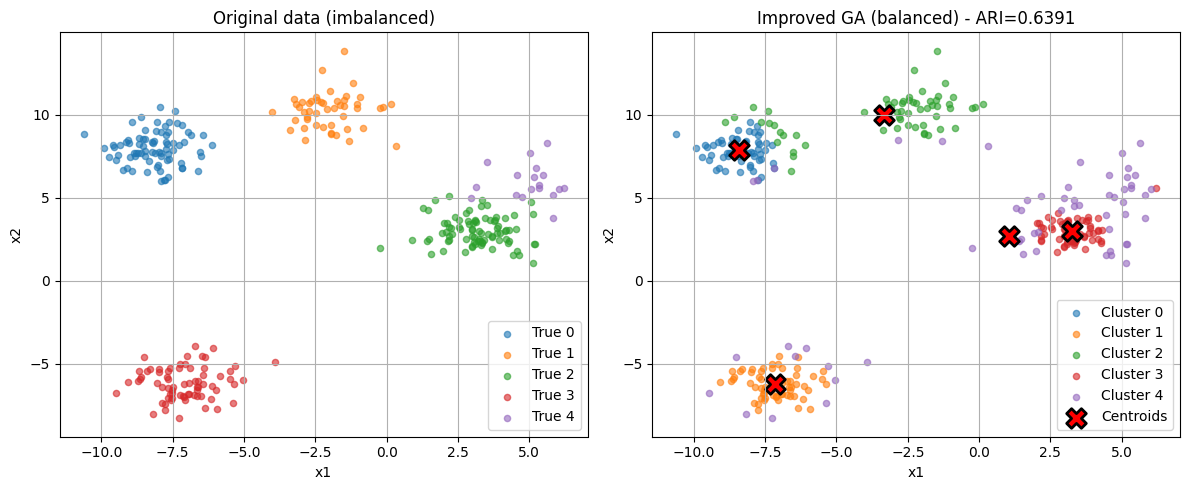


Cluster sizes after GA: [np.int64(60), np.int64(60), np.int64(60), np.int64(60), np.int64(60)]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans


# 1) Charger le dataset imbalanced

data = np.load("balanced_kmeans_data_imbalanced.npz")
X = data["X"]
y_true = data["y_true"]
N = int(data["N"])
K = int(data["K"])
s = int(data["s"])
samples_per_center = data["samples_per_center"]

print("Loaded dataset:", X.shape, "points")
print("K:", K)
print("Target balanced size s = N/K =", s)
print("True (imbalanced) sizes per center:", samples_per_center.tolist())

unique_labels, counts = np.unique(y_true, return_counts=True)
print("True cluster sizes (from y_true):", dict(zip(unique_labels, counts)))


# 2) Fonctions utilitaires


def compute_centroids(X, z, K):
    d = X.shape[1]
    centroids = np.zeros((K, d))
    for k in range(K):
        idx = np.where(z == k)[0]
        if len(idx) > 0:
            centroids[k] = X[idx].mean(axis=0)
    return centroids

def wcss(X, z, K):
    centroids = compute_centroids(X, z, K)
    total = 0.0
    for k in range(K):
        idx = np.where(z == k)[0]
        if len(idx) > 0:
            diff = X[idx] - centroids[k]
            total += np.sum(diff ** 2)
    return total

def fitness_from_wcss(val):
    return 1.0 / (1.0 + val)

# 3) Initialisation intelligente

def kmeans_based_init(X, K, s, n_inits=10):
    """Initialise avec K-means standard puis balance"""
    best_z = None
    best_wcss = np.inf

    for _ in range(n_inits):
        kmeans = KMeans(n_clusters=K, n_init=1)
        z_unbalanced = kmeans.fit_predict(X)
        z_balanced = balance_assignment(X, z_unbalanced, K, s)
        w = wcss(X, z_balanced, K)
        if w < best_wcss:
            best_wcss = w
            best_z = z_balanced

    return best_z

def balance_assignment(X, z, K, s):
    """Balance une assignation non-équilibrée en réassignant les points excédentaires"""
    z = z.copy()
    centroids = compute_centroids(X, z, K)

    counts = np.array([np.sum(z == k) for k in range(K)])

    # Identifier clusters en surplus et en déficit
    while True:
        surplus = np.where(counts > s)[0]
        deficit = np.where(counts < s)[0]

        if len(surplus) == 0:
            break

        # Pour chaque cluster en surplus
        for k_sur in surplus:
            while counts[k_sur] > s and len(deficit) > 0:
                # Trouver les points du cluster en surplus
                idx_sur = np.where(z == k_sur)[0]

                # Calculer distances aux centroides des clusters en déficit
                k_def = deficit[0]

                # Trouver le point le plus proche du centroide du cluster en déficit
                dists = np.linalg.norm(X[idx_sur] - centroids[k_def], axis=1)
                farthest_from_current = np.argmax(np.linalg.norm(X[idx_sur] - centroids[k_sur], axis=1))
                i_move = idx_sur[farthest_from_current]

                # Réassigner
                z[i_move] = k_def
                counts[k_sur] -= 1
                counts[k_def] += 1

                if counts[k_def] == s:
                    deficit = deficit[1:]

        # Recalculer pour éviter boucle infinie
        counts = np.array([np.sum(z == k) for k in range(K)])

    return z

def init_population_smart(X, K, s, pop_size, seed=None):
    """Initialisation mixte : 50% K-means based, 50% random"""
    if seed is not None:
        np.random.seed(seed)

    N = X.shape[0]
    population = []

    # 50% initialisations intelligentes
    for _ in range(pop_size // 2):
        z = kmeans_based_init(X, K, s, n_inits=3)
        population.append(z)

    # 50% initialisations aléatoires
    for _ in range(pop_size - len(population)):
        labels = np.repeat(np.arange(K), s)
        np.random.shuffle(labels)
        population.append(labels)

    return np.array(population)


# 4) Local search (Lloyd-like refinement)


def local_search_balanced(X, z, K, s, max_iters=10):
    """Amélioration locale type Lloyd avec contrainte d'équilibre"""
    z = z.copy()

    for _ in range(max_iters):
        old_z = z.copy()
        centroids = compute_centroids(X, z, K)

        # Calculer distances de tous les points à tous les centroides
        distances = np.array([[np.linalg.norm(X[i] - centroids[k])
                              for k in range(K)] for i in range(len(X))])

        # Réassignation équilibrée par Hungarian-like approach
        z_new = balanced_assignment_hungarian(distances, K, s)
        z = z_new

        if np.array_equal(z, old_z):
            break

    return z

def balanced_assignment_hungarian(distances, K, s):
    """Assignation équilibrée minimisant la distance totale"""
    N = distances.shape[0]
    z = np.zeros(N, dtype=int)

    # Pour chaque cluster, sélectionner les s points les plus proches
    assigned = np.zeros(N, dtype=bool)

    for k in range(K):
        available = np.where(~assigned)[0]
        if len(available) == 0:
            break

        # Prendre les s points disponibles les plus proches du centroide k
        dists_k = distances[available, k]
        n_to_assign = min(s, len(available))
        closest_idx = np.argpartition(dists_k, n_to_assign-1)[:n_to_assign]

        points_to_assign = available[closest_idx]
        z[points_to_assign] = k
        assigned[points_to_assign] = True

    return z

# 5) Opérateurs génétiques améliorés


def tournament_selection(pop, fitness, tournament_size=3):
    """Sélection par tournoi (meilleure que roulette)"""
    pop_size = len(pop)
    selected = []

    for _ in range(pop_size):
        tournament_idx = np.random.choice(pop_size, size=tournament_size, replace=False)
        tournament_fitness = fitness[tournament_idx]
        winner_idx = tournament_idx[np.argmax(tournament_fitness)]
        selected.append(pop[winner_idx])

    return np.array(selected)

def cluster_aware_mutation(X, z, K, s):
    """Mutation qui déplace un point vers le cluster le plus proche"""
    z = z.copy()
    centroids = compute_centroids(X, z, K)

    # Choisir un cluster source et destination aléatoirement
    k_src = np.random.randint(K)
    k_dst = np.random.randint(K)

    if k_src == k_dst:
        return z

    idx_src = np.where(z == k_src)[0]
    idx_dst = np.where(z == k_dst)[0]

    if len(idx_src) == 0 or len(idx_dst) == 0:
        return z

    # Trouver le point de k_src le plus proche du centroide de k_dst
    dists = np.linalg.norm(X[idx_src] - centroids[k_dst], axis=1)
    i_move_src = idx_src[np.argmin(dists)]

    # Trouver le point de k_dst le plus proche du centroide de k_src
    dists = np.linalg.norm(X[idx_dst] - centroids[k_src], axis=1)
    i_move_dst = idx_dst[np.argmin(dists)]

    # Échanger
    z[i_move_src] = k_dst
    z[i_move_dst] = k_src

    return z


# 6) Balanced K-means GA amélioré


def balanced_kmeans_ga_improved(
    X, K, generations=100, pop_size=50, pc=0.9, pm=0.4,
    local_search_prob=0.3, seed=None
):
    if seed is not None:
        np.random.seed(seed)

    N = X.shape[0]
    s = N // K

    # Initialisation intelligente
    population = init_population_smart(X, K, s, pop_size, seed=seed)

    wcss_vals = np.array([wcss(X, z, K) for z in population])
    fitness = np.array([fitness_from_wcss(v) for v in wcss_vals])

    best_idx = np.argmax(fitness)
    best_z = population[best_idx].copy()
    best_wcss = wcss_vals[best_idx]

    history = [best_wcss]
    no_improve_count = 0

    for gen in range(generations):
        # Sélection par tournoi
        mating_pool = tournament_selection(population, fitness, tournament_size=3)

        # Crossover
        new_pop = []
        for i in range(0, pop_size, 2):
            p1 = mating_pool[i]
            p2 = mating_pool[(i + 1) % pop_size]
            if np.random.rand() < pc:
                c1, c2 = balanced_crossover_uniform(p1, p2, K, s)
            else:
                c1, c2 = p1.copy(), p2.copy()
            new_pop.extend([c1, c2])
        population = np.array(new_pop[:pop_size])

        # Mutation améliorée
        for i in range(pop_size):
            if np.random.rand() < pm:
                population[i] = cluster_aware_mutation(X, population[i], K, s)

        # Local search sur une partie de la population
        for i in range(pop_size):
            if np.random.rand() < local_search_prob:
                population[i] = local_search_balanced(X, population[i], K, s, max_iters=5)

        # Élitisme : garder le meilleur
        population[0] = best_z.copy()

        wcss_vals = np.array([wcss(X, z, K) for z in population])
        fitness = np.array([fitness_from_wcss(v) for v in wcss_vals])

        gen_best_idx = np.argmin(wcss_vals)
        gen_best_wcss = wcss_vals[gen_best_idx]

        if gen_best_wcss < best_wcss:
            best_wcss = gen_best_wcss
            best_z = population[gen_best_idx].copy()
            no_improve_count = 0
        else:
            no_improve_count += 1

        history.append(best_wcss)

        # Adaptive mutation
        if no_improve_count > 10:
            pm = min(0.6, pm * 1.1)
        else:
            pm = max(0.2, pm * 0.95)

    return best_z, best_wcss, np.array(history)

def balanced_crossover_uniform(parent1, parent2, K, s):
    """Crossover uniforme avec réparation"""
    N = len(parent1)
    mask = np.random.rand(N) < 0.5
    child1 = np.where(mask, parent1, parent2)
    child2 = np.where(mask, parent2, parent1)
    child1 = balance_assignment_fast(child1, K, s)
    child2 = balance_assignment_fast(child2, K, s)
    return child1, child2

def balance_assignment_fast(z, K, s):
    """Version rapide du balancing"""
    z = z.copy()
    counts = np.array([np.sum(z == k) for k in range(K)])
    positions = [np.where(z == k)[0].tolist() for k in range(K)]

    while True:
        surplus = [k for k in range(K) if counts[k] > s]
        deficit = [k for k in range(K) if counts[k] < s]

        if not surplus:
            break

        for k_sur in surplus:
            while counts[k_sur] > s and deficit:
                i = positions[k_sur].pop()
                counts[k_sur] -= 1

                k_def = deficit[0]
                z[i] = k_def
                positions[k_def].append(i)
                counts[k_def] += 1

                if counts[k_def] == s:
                    deficit.pop(0)
    return z


# 7) Exécution des tests


num_runs = 20
generations = 100

all_wcss = []
all_ari = []
all_iters = []
histories = []

print("\n=== Running improved GA ===")
for r in range(num_runs):
    z_best, w_best, hist = balanced_kmeans_ga_improved(
        X, K, generations=generations, pop_size=50, pc=0.9, pm=0.4,
        local_search_prob=0.3, seed=100 + r
    )
    all_wcss.append(w_best)
    ari = adjusted_rand_score(y_true, z_best)
    all_ari.append(ari)
    all_iters.append(len(hist) - 1)
    histories.append(hist)

    if (r + 1) % 5 == 0:
        print(f"Run {r+1}/{num_runs}: WCSS={w_best:.2f}, ARI={ari:.4f}")

all_wcss = np.array(all_wcss)
all_ari = np.array(all_ari)
all_iters = np.array(all_iters)

print("\n=== RESULTS (Improved Version) ===")
print(f"WCSS mean ± std: {all_wcss.mean():.2f} ± {all_wcss.std():.2f}")
print(f"ARI  mean ± std: {all_ari.mean():.4f} ± {all_ari.std():.4f}")
print(f"Best WCSS: {all_wcss.min():.2f}")
print(f"Best ARI: {all_ari.max():.4f}")


# 8) Visualisations


# Convergence
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
for i in range(min(10, num_runs)):
    plt.plot(histories[i], alpha=0.5)
plt.xlabel("Generation")
plt.ylabel("Best WCSS")
plt.title("Convergence curves (Improved GA)")
plt.grid(True)

# Boxplots comparatifs
plt.subplot(1, 2, 2)
plt.boxplot([all_wcss, all_ari * 10000], labels=['WCSS/100', 'ARI×10000'])
plt.ylabel("Value")
plt.title("Distribution over 20 runs")
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

# Meilleur résultat
best_run_idx = np.argmax(all_ari)
z_best_vis, _, _ = balanced_kmeans_ga_improved(
    X, K, generations=generations, pop_size=50, pc=0.9, pm=0.4,
    local_search_prob=0.3, seed=100 + best_run_idx
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for k in unique_labels:
    idx = np.where(y_true == k)[0]
    plt.scatter(X[idx, 0], X[idx, 1], s=20, alpha=0.6, label=f"True {k}")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Original data (imbalanced)")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for k in range(K):
    idx = np.where(z_best_vis == k)[0]
    plt.scatter(X[idx, 0], X[idx, 1], s=20, alpha=0.6, label=f"Cluster {k}")
centroids = compute_centroids(X, z_best_vis, K)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X',
            edgecolors='black', linewidths=2, label='Centroids')
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"Improved GA (balanced) - ARI={all_ari[best_run_idx]:.4f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nCluster sizes after GA:", [np.sum(z_best_vis == k) for k in range(K)])